# Analysis

In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/consumer_complaints.csv')

sns.set_theme(palette='Greens_d')

df.info()

df.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 891366 entries, 0 to 891365
Data columns (total 11 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   date_received                 891366 non-null  str  
 1   product                       891366 non-null  str  
 2   issue                         891366 non-null  str  
 3   company                       891366 non-null  str  
 4   state                         891366 non-null  str  
 5   submitted_via                 891366 non-null  str  
 6   date_sent_to_company          891366 non-null  str  
 7   company_response_to_consumer  891366 non-null  str  
 8   timely_response               891366 non-null  str  
 9   consumer_disputed             891366 non-null  str  
 10  complaint_id                  891366 non-null  int64
dtypes: int64(1), str(10)
memory usage: 74.8 MB


date_received                     2176
product                             18
issue                              166
company                           4485
state                               54
submitted_via                        6
date_sent_to_company              2125
company_response_to_consumer         8
timely_response                      2
consumer_disputed                    3
complaint_id                    891366
dtype: int64

## Which financial products generate the most complaints?

product
Mortgage                                                                        239642
Debt collection                                                                 169743
Credit reporting                                                                139127
Credit card                                                                      88023
Bank account or service                                                          84275
Credit reporting, credit repair services, or other personal consumer reports     57957
Student loan                                                                     38145
Consumer Loan                                                                    31291
Credit card or prepaid card                                                      11495
Checking or savings account                                                       9304
Payday loan                                                                       5519
Money transfers                    

Text(0.5, 1.0, 'Number of Complaints Sorted by Products')

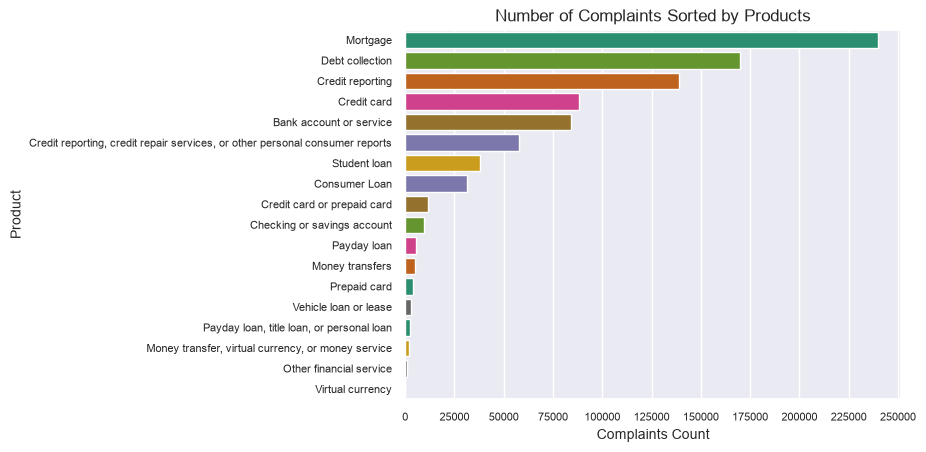

In [40]:
print(df['product'].value_counts())
print(np.around(df['product'].value_counts() / df.shape[0] * 100, 2))

g = sns.countplot(data=df, y='product', hue='product', legend=False, palette='Dark2', order=df['product'].value_counts().index)
g.set_xticks(np.arange(0, 250001, 25000))
g.tick_params(axis='both', labelsize=8)

g.set_xlabel('Complaints Count', fontsize=10)
g.set_ylabel('Product', fontsize=10)
g.set_title('Number of Complaints Sorted by Products')

## How have complaint volumes changed over time?

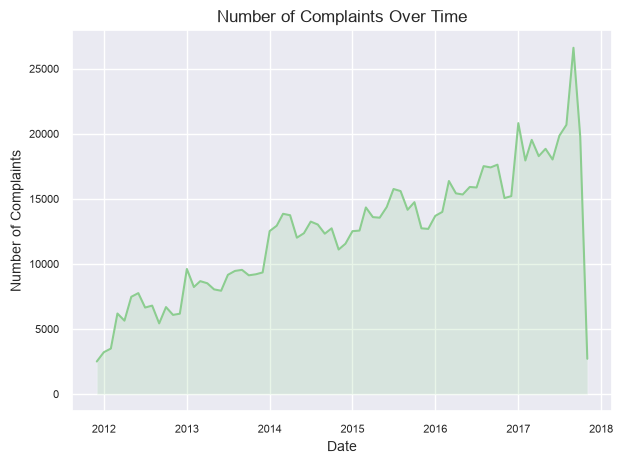

In [63]:
df['date_received'] = pd.to_datetime(df['date_received'])

monthly_complaints = df.set_index('date_received').resample('MS').size()

sns.lineplot(x=monthly_complaints.index, y=monthly_complaints.values)
plt.fill_between(monthly_complaints.index, monthly_complaints.values, alpha=0.2)

plt.tick_params(axis='both', labelsize=8)

plt.title('Number of Complaints Over Time')
plt.xlabel('Date', fontsize=10)
plt.ylabel('Number of Complaints', fontsize=10)
plt.tight_layout()

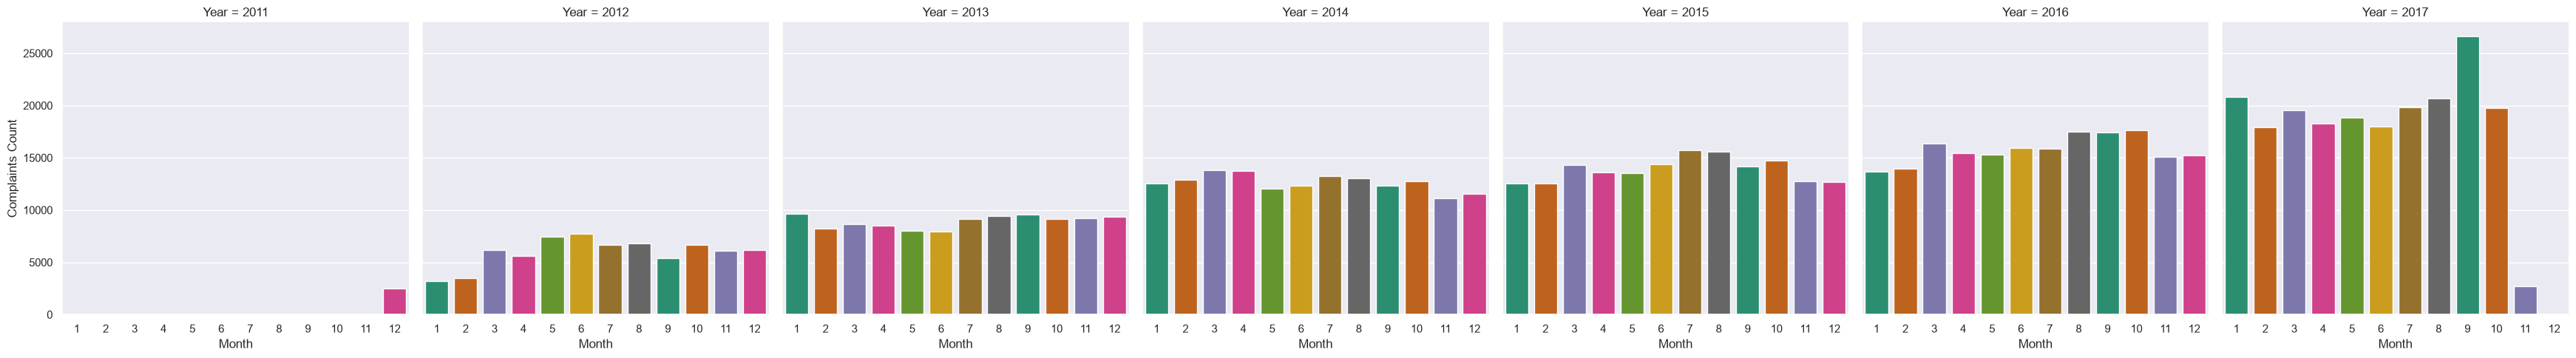

In [67]:
df['year'] = df['date_received'].dt.year
df['month'] = df['date_received'].dt.month

f = sns.catplot(data=df, x='month', col='Year', hue='month', kind='count', legend=False, palette='Dark2')

f.set_axis_labels('Month', 'Complaints Count')